[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_crps/BA_L4_crps.ipynb)

# BA_L4_crps: CRPS and the Threshold Weight of twCRPS

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Continuous ranked probability score (CRPS) as the squared gap between a forecast CDF and the step function of the outcome, and the logistic threshold weight of the threshold-weighted CRPS (twCRPS) around plus or minus 15 basis points; worked example with three forecasts and three outcomes. Analytical, no data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

The continuous ranked probability score ([Gneiting & Raftery, 2007](https://doi.org/10.1198/016214506000001437)) is a proper scoring rule for a forecast given by its cumulative distribution function (CDF) $F$, or its quantile function $Q = F^{-1}$, and an outcome $y$:

$$ \mathrm{CRPS}(F, y) = \int_{-\infty}^{\infty} \big(F(x) - \mathbb 1\{y \leq x\}\big)^2 dx = 2\int_0^1 \rho_u\big(y - Q(u)\big)\,du, $$

where $\rho_u(e) = e\,(u - \mathbb 1\{e < 0\})$ is the pinball loss. For a Normal forecast, $\mathrm{CRPS}(N(\mu, \sigma^2), y) = \sigma\big[z(2\Phi(z) - 1) + 2\varphi(z) - 1/\sqrt\pi\big]$ with $z = (y - \mu)/\sigma$.
The threshold-weighted CRPS ([Gneiting & Ranjan, 2011](https://doi.org/10.1198/jbes.2010.08110)) puts the weight where depegs are:

$$ \mathrm{twCRPS} = 2\int_0^1 \rho_u\big(v(y) - v(Q(u))\big)\,du, \quad v(r) = \int_0^r w(s)\,ds, \quad w(r) = \sigma\Big(\frac{r - \delta}{h}\Big) + \sigma\Big(\frac{-r - \delta}{h}\Big), $$

with $\sigma(z) = 1/(1 + e^{-z})$ the logistic function and $h$ the width over which the weight rises around $\pm\delta$.

Left: the CRPS as the squared gap between the forecast CDF $N(0, 5^2)$ and the outcome $y = 12$ basis points (bp). Right: the weight $w(r)$ for $\delta = 15$ bp and $h = 2$.

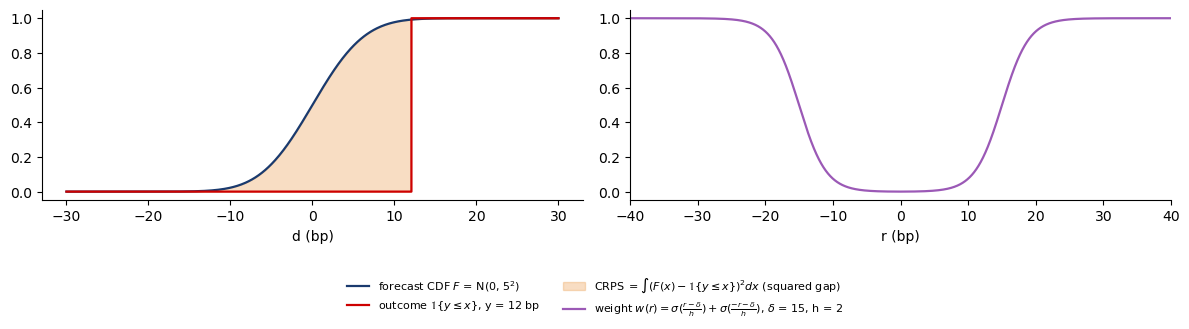

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
xs = np.linspace(-30, 30, 600)
sig = lambda r: 1 / (1 + np.exp(-r))
delta, hh = 15.0, 2.0
rr = np.linspace(-60, 60, 24001)
wfun = sig((rr - delta) / hh) + sig((-rr - delta) / hh)
ax[0].plot(xs, stats.norm.cdf(xs, 0, 5), color=BLUE, lw=1.6, label=r'forecast CDF $F$ = N(0, 5$^2$)')
ax[0].step(xs, (xs >= 12).astype(float), color=RED, lw=1.6, where='post', label=r'outcome $\mathbb{1}\{y \leq x\}$, y = 12 bp')
ax[0].fill_between(xs, stats.norm.cdf(xs, 0, 5), (xs >= 12).astype(float), color=BTC, alpha=0.3,
                   label=r'CRPS $= \int (F(x) - \mathbb{1}\{y \leq x\})^2 dx$ (squared gap)')
ax[0].set_xlabel('d (bp)')
ax[1].plot(rr, wfun, color=ETH, lw=1.6, label=r'weight $w(r) = \sigma(\frac{r-\delta}{h}) + \sigma(\frac{-r-\delta}{h})$, $\delta$ = 15, h = 2')
ax[1].set_xlabel('r (bp)'); ax[1].set_xlim(-40, 40)
save(fig, 'ba_l4_crps', 0.2, ncol=2)

## Key numbers: three forecasts, three outcomes

The integrals over $u$ are approximated on 999 equally spaced levels.

In [6]:
def crps_norm(mu, s, y):
    z = (y - mu) / s
    return s * (z * (2 * stats.norm.cdf(z) - 1) + 2 * stats.norm.pdf(z) - 1 / np.sqrt(np.pi))


u = (np.arange(1, 1000) - 0.5) / 999
pin = lambda uu, e: e * (uu - (e < 0))
Vc = np.concatenate([[0], np.cumsum((wfun[1:] + wfun[:-1]) / 2 * np.diff(rr))])
Vc -= np.interp(0, rr, Vc)
vt = lambda r: np.interp(r, rr, Vc)
crps_q = lambda q, y: 2 * (pin(u, y - q)).mean()
tw_q = lambda q, y: 2 * (pin(u, vt(y) - vt(q))).mean()
rows = {}
for name, q in [('N(0, 5^2)', stats.norm.ppf(u, 0, 5)), ('N(0, 10^2)', stats.norm.ppf(u, 0, 10)), ('t3, scale 3', stats.t.ppf(u, 3) * 3)]:
    rows[name] = {**{f'CRPS, y = {y:g}': crps_q(q, y) for y in [1, 12, 25]}, **{f'twCRPS, y = {y:g}': tw_q(q, y) for y in [1, 12, 25]}}
print(f'closed-form CRPS of N(0, 5^2) at y = 12: {crps_norm(0, 5, 12):.3f}')
pd.DataFrame(rows).T.round(3)

closed-form CRPS of N(0, 5^2) at y = 12: 9.206


,"CRPS, y = 1","CRPS, y = 12","CRPS, y = 25","twCRPS, y = 1","twCRPS, y = 12","twCRPS, y = 25"
"N(0, 5^2)",1.248,9.206,22.180,0.003,0.378,9.980
"N(0, 10^2)",2.377,7.480,19.398,0.054,0.324,9.343
"t3, scale 3",0.948,9.705,22.566,0.003,0.381,9.910


**How to read it:** in a calm hour ($y = 1$) the sharp forecasts win; in a depeg hour ($y = 25$) the wide one wins. The twCRPS downweights calm hours (0.003 against a CRPS of 1.25 for $y = 1$) and concentrates the score on the depeg region.